# Notebook 10: Component distribution overlap and revised Figure 3

Two requests are handled here.

**Component overlap.** "Overlap" can mean two different things for an NMF embedding, and they answer different questions, so both are computed and reported separately:

- **Between-component overlap** — do comp_1 and comp_4 describe the same underlying variation? Measured as cosine similarity between their feature loadings (H), Spearman correlation between their participant loadings (W), and the overlap coefficient of their loading distributions. Low overlap supports the manuscript's claim that the sex signal is carried by *two distinct* components rather than one pattern appearing twice.
- **Within-component separation by sex** — for comp_1 and comp_4 individually, how far apart are the male and female loading distributions? Measured as the overlap coefficient (OVL), the Bhattacharyya coefficient, and AUC, each with a bootstrap confidence interval.

Both are reported for all five components, not just the two sex-bearing ones, so the comparison has a baseline.

**Revised Figure 3.** Regenerated with larger, consistently sized type throughout — every text element is driven by the `FONT` block below, so a single edit rescales the whole figure. Panel B is redrawn as density curves rather than raw histograms, which is what makes distributional overlap legible.

**Inputs:** `outputs/nmf_W.csv`, `outputs/nmf_H.csv`, `outputs/metadata.csv`

**Outputs:** `outputs/component_overlap_between.csv`, `outputs/component_overlap_by_sex.csv`, `outputs/figure3_revised.png` (and `.pdf`), `outputs/component_overlap.png`

## Setup

In [1]:
import pandas as pd
import numpy as np
from pathlib import Path
from scipy import stats
from itertools import combinations
import matplotlib.pyplot as plt
import matplotlib as mpl
import warnings
warnings.filterwarnings("ignore")

PROJECT_ROOT = Path(".").resolve().parent
OUTPUT_DIR = PROJECT_ROOT / "outputs"

FREQ_BANDS = ["Theta", "Alpha", "BetaL", "BetaH", "Gamma"]
CHANNELS = ["AF3", "F7", "F3", "FC5", "T7", "P7", "O1",
            "O2", "P8", "T8", "FC6", "F4", "F8", "AF4"]

SEX_COL = "Gender"
SEX_ORDER = ["F", "M"]          # positive effect = higher in females
SEX_LABELS = {"F": "Female", "M": "Male"}
SEX_COLOURS = {"F": "#B5446E", "M": "#2E86AB"}

N_BOOTSTRAP = 2000
RANDOM_SEED = 42
GRID_POINTS = 512

# ---- Figure typography. Change these numbers to rescale all text at once. ----
FONT = {
    "base":        14,   # default text
    "axis_label":  15,
    "tick":        13,
    "panel_title": 17,
    "panel_letter":19,
    "legend":      13,
    "annotation":  12,
}

report = []
def log(msg=""):
    print(msg); report.append(str(msg))

## Load

In [2]:
W = pd.read_csv(OUTPUT_DIR / "nmf_W.csv", index_col="participant_id")
H = pd.read_csv(OUTPUT_DIR / "nmf_H.csv", index_col=0)
metadata = pd.read_csv(OUTPUT_DIR / "metadata.csv").set_index("participant_id").reindex(W.index)
sex = metadata[SEX_COL]
components = list(W.columns)

assert (W.index == metadata.index).all()
log(f"W: {W.shape}, H: {H.shape}")
log(f"Components: {components}")
log(f"Sex: {dict(sex.value_counts())}")

def parse_feature(name):
    cat, pow_part = name.split("__", 1)
    _, ch, band = pow_part.split(".")
    return cat, ch, band

W: (86, 5), H: (5, 350)
Components: ['comp_1', 'comp_2', 'comp_3', 'comp_4', 'comp_5']
Sex: {'M': 44, 'F': 42}


## Overlap measures

The **overlap coefficient (OVL)** is the area shared by two probability densities: it runs from 0 (disjoint) to 1 (identical). The **Bhattacharyya coefficient** is a related but smoother measure of distributional affinity. **AUC** is the probability that a randomly chosen female participant has a higher loading than a randomly chosen male participant, and relates to the Mann–Whitney statistic directly, so it ties back to the effect sizes already reported in the manuscript.

Densities are estimated by Gaussian KDE on a shared grid. KDE bandwidth affects OVL, so the same bandwidth rule is applied everywhere and the raw histogram-based estimate is reported alongside as a check that the conclusion is not an artefact of smoothing.

In [3]:
rng = np.random.default_rng(RANDOM_SEED)

def densities(a, b, grid_points=GRID_POINTS):
    lo = min(a.min(), b.min()); hi = max(a.max(), b.max())
    pad = 0.05 * (hi - lo) if hi > lo else 1.0
    grid = np.linspace(lo - pad, hi + pad, grid_points)
    ka, kb = stats.gaussian_kde(a), stats.gaussian_kde(b)
    return grid, ka(grid), kb(grid)

def ovl_kde(a, b):
    grid, da, db = densities(a, b)
    return float(np.trapz(np.minimum(da, db), grid))

def ovl_hist(a, b, bins=20):
    lo = min(a.min(), b.min()); hi = max(a.max(), b.max())
    edges = np.linspace(lo, hi, bins + 1)
    ha, _ = np.histogram(a, bins=edges, density=True)
    hb, _ = np.histogram(b, bins=edges, density=True)
    return float(np.sum(np.minimum(ha, hb)) * np.diff(edges)[0])

def bhattacharyya(a, b):
    grid, da, db = densities(a, b)
    return float(np.trapz(np.sqrt(da * db), grid))

def auc_female_higher(a_f, a_m):
    u, _ = stats.mannwhitneyu(a_f, a_m, alternative="two-sided")
    return float(u / (len(a_f) * len(a_m)))

def bootstrap_ci(fn, a, b, n=N_BOOTSTRAP, alpha=0.05):
    """Stratified bootstrap over the two groups independently."""
    vals = np.empty(n)
    for i in range(n):
        ra = rng.choice(a, size=len(a), replace=True)
        rb = rng.choice(b, size=len(b), replace=True)
        try:
            vals[i] = fn(ra, rb)
        except Exception:
            vals[i] = np.nan
    vals = vals[~np.isnan(vals)]
    return float(np.percentile(vals, 100 * alpha / 2)), float(np.percentile(vals, 100 * (1 - alpha / 2)))

### Between-component overlap

In [4]:
rows = []
for c1, c2 in combinations(components, 2):
    h1, h2 = H.loc[c1].values, H.loc[c2].values
    cos = float(h1 @ h2 / (np.linalg.norm(h1) * np.linalg.norm(h2)))
    rho, p_rho = stats.spearmanr(W[c1], W[c2])
    rows.append({
        "component_a": c1, "component_b": c2,
        "H_cosine_similarity": cos,
        "W_spearman_rho": float(rho), "W_spearman_p": float(p_rho),
        "W_distribution_OVL": ovl_kde(W[c1].values, W[c2].values),
    })
between = pd.DataFrame(rows).sort_values("H_cosine_similarity", ascending=False).reset_index(drop=True)
between.to_csv(OUTPUT_DIR / "component_overlap_between.csv", index=False)
log("Between-component overlap (all pairs, sorted by feature-space similarity):")
log(between.round(4).to_string(index=False))

pair14 = between[((between["component_a"] == "comp_1") & (between["component_b"] == "comp_4")) |
                 ((between["component_a"] == "comp_4") & (between["component_b"] == "comp_1"))]
if len(pair14):
    r14 = pair14.iloc[0]
    others = between.drop(pair14.index)
    log(f"\ncomp_1 vs comp_4: H cosine = {r14['H_cosine_similarity']:.4f}, "
        f"W Spearman ρ = {r14['W_spearman_rho']:+.4f} (p = {r14['W_spearman_p']:.4f})")
    log(f"Median H cosine across the other {len(others)} pairs: "
        f"{others['H_cosine_similarity'].median():.4f}")
    if r14["H_cosine_similarity"] < others["H_cosine_similarity"].median():
        log("comp_1 and comp_4 are LESS similar to each other than the typical component pair —")
        log("they are capturing distinct spatial-spectral patterns, which supports the claim that")
        log("the sex signal is carried by two separable components rather than one duplicated one.")
    else:
        log("[CHECK] comp_1 and comp_4 are MORE similar than the typical pair. The two-component")
        log("        framing needs care: they may be partially redundant.")

Between-component overlap (all pairs, sorted by feature-space similarity):
component_a component_b  H_cosine_similarity  W_spearman_rho  W_spearman_p  W_distribution_OVL
     comp_1      comp_4               0.6921         -0.0957        0.3809              0.8144
     comp_1      comp_2               0.6329         -0.0309        0.7773              0.8630
     comp_2      comp_4               0.6085          0.0618        0.5719              0.8207
     comp_3      comp_4               0.5939          0.1134        0.2984              0.8343
     comp_1      comp_3               0.5877         -0.0002        0.9984              0.7391
     comp_1      comp_5               0.5553         -0.1150        0.2918              0.7195
     comp_2      comp_3               0.5442          0.0368        0.7369              0.7436
     comp_4      comp_5               0.5174          0.2622        0.0147              0.8010
     comp_3      comp_5               0.5088          0.1324        0.

### Within-component separation by sex

In [5]:
rows = []
for comp in components:
    f = W.loc[sex == SEX_ORDER[0], comp].values
    m = W.loc[sex == SEX_ORDER[1], comp].values
    ovl = ovl_kde(f, m)
    ovl_lo, ovl_hi = bootstrap_ci(ovl_kde, f, m)
    auc = auc_female_higher(f, m)
    auc_lo, auc_hi = bootstrap_ci(auc_female_higher, f, m)
    _, p_mw = stats.mannwhitneyu(f, m, alternative="two-sided")
    rows.append({
        "component": comp, "n_female": len(f), "n_male": len(m),
        "median_female": float(np.median(f)), "median_male": float(np.median(m)),
        "OVL_kde": ovl, "OVL_kde_lo": ovl_lo, "OVL_kde_hi": ovl_hi,
        "OVL_hist": ovl_hist(f, m),
        "bhattacharyya": bhattacharyya(f, m),
        "AUC_female_higher": auc, "AUC_lo": auc_lo, "AUC_hi": auc_hi,
        "rank_biserial": 2 * auc - 1,
        "p_mannwhitney": float(p_mw),
    })
by_sex = pd.DataFrame(rows).sort_values("OVL_kde").reset_index(drop=True)
by_sex.to_csv(OUTPUT_DIR / "component_overlap_by_sex.csv", index=False)
log("Male/female loading distribution overlap, per component (lower OVL = better separation):")
log(by_sex[["component", "median_female", "median_male", "OVL_kde", "OVL_kde_lo", "OVL_kde_hi",
            "OVL_hist", "AUC_female_higher", "AUC_lo", "AUC_hi", "rank_biserial",
            "p_mannwhitney"]].round(4).to_string(index=False))

log("\nNote on magnitude: an OVL near 0.6-0.8 is entirely normal for a real group difference")
log("in a sample of this size. A component can carry a robust, FDR-surviving sex association")
log("and still have heavily overlapping distributions — the two are not in tension. Separation")
log("at the level of individual classification would require OVL far lower than anything")
log("plausible here, and the manuscript should not be read as claiming that.")

Male/female loading distribution overlap, per component (lower OVL = better separation):
component  median_female  median_male  OVL_kde  OVL_kde_lo  OVL_kde_hi  OVL_hist  AUC_female_higher  AUC_lo  AUC_hi  rank_biserial  p_mannwhitney
   comp_1         0.5386       0.1908   0.5501      0.4035      0.6719    0.5152             0.7884  0.6813  0.8831         0.5768         0.0000
   comp_4         0.1837       0.3550   0.7227      0.5539      0.8264    0.6234             0.3428  0.2237  0.4573        -0.3144         0.0122
   comp_5         0.1405       0.1634   0.8398      0.6742      0.8449    0.7100             0.4713  0.3506  0.6004        -0.0574         0.6498
   comp_3         0.2152       0.1730   0.8491      0.6853      0.8729    0.7554             0.5200  0.3907  0.6396         0.0400         0.7523
   comp_2         0.3857       0.2969   0.8604      0.6914      0.8893    0.7132             0.5666  0.4491  0.6835         0.1331         0.2898

Note on magnitude: an OVL near 0.6

## Overlap figure

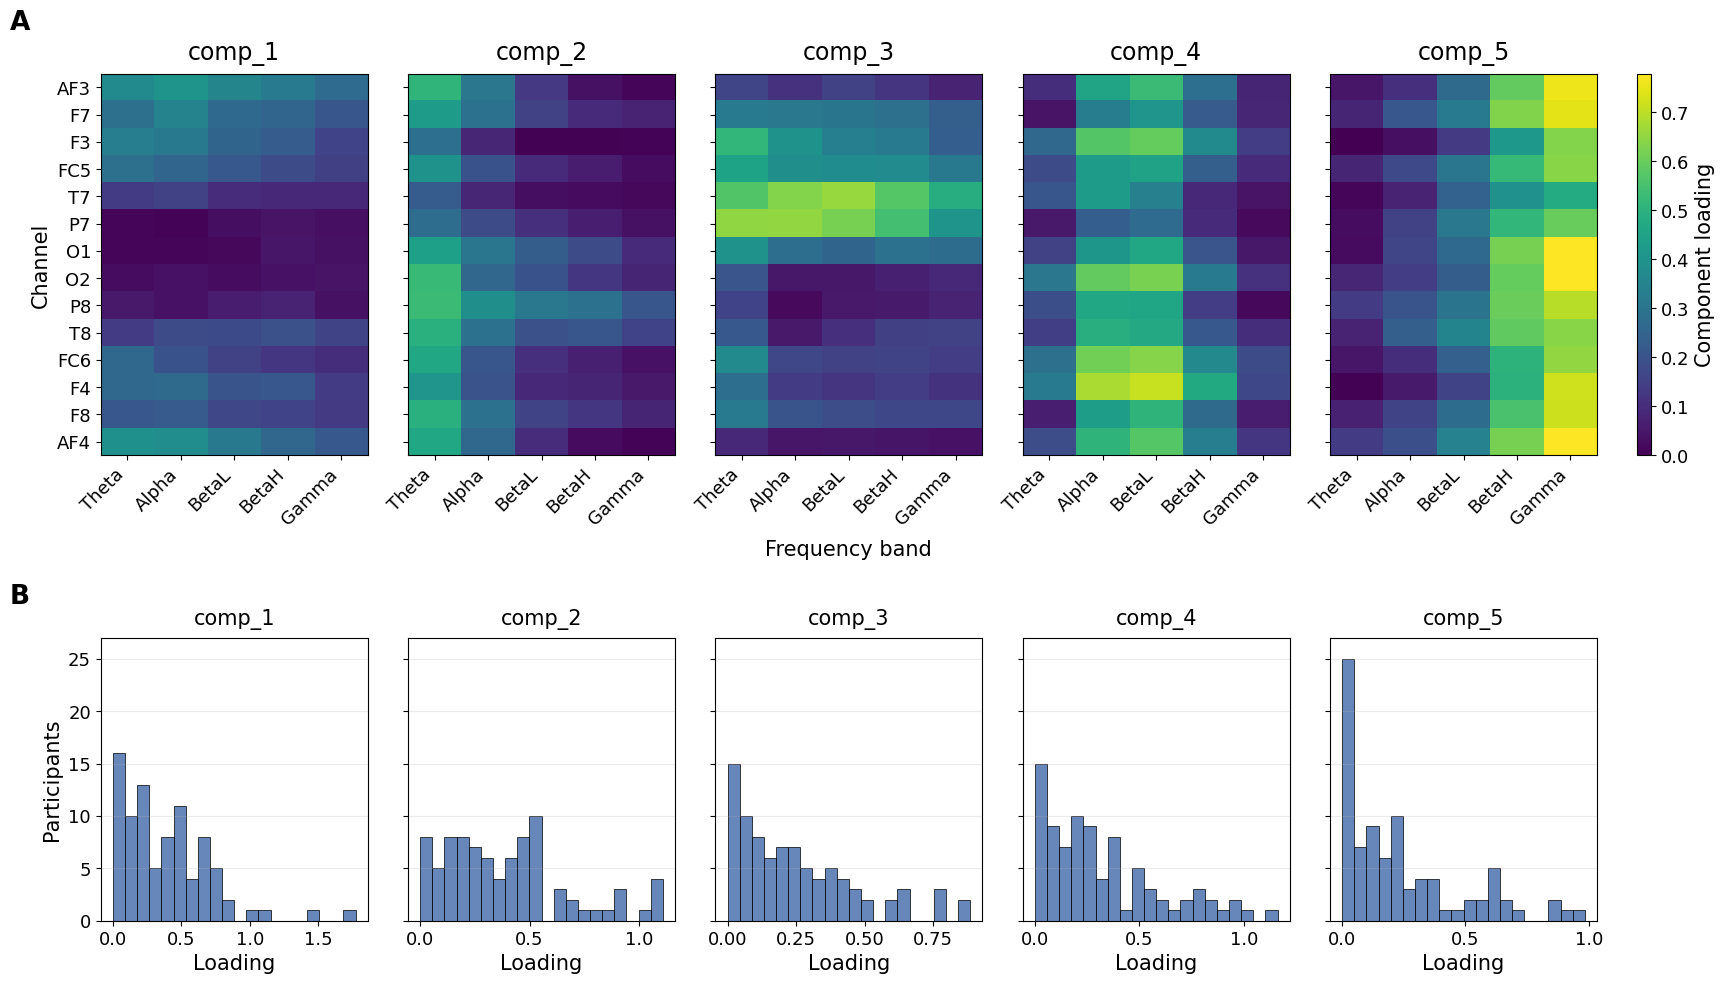

Saved figure3_revised.png (300 dpi) and figure3_revised.pdf
Panel B is pooled across participants — no sex split — so the existing Figure 3
caption stands unchanged.


In [6]:
# Replacement for the "Revised Figure 3" cell in 10_component_overlap_figure3.ipynb.
# Panel B reverted to pooled histograms (no sex split) — Figure 3 sits in Section 3.1,
# which precedes the introduction of sex in 3.3. Typography and spacing fixes retained.
# Depends on: W, H, components, parse_feature(), FONT, CHANNELS, FREQ_BANDS, OUTPUT_DIR, log()

mpl.rcParams.update({
    "font.size": FONT["base"],
    "axes.labelsize": FONT["axis_label"],
    "axes.titlesize": FONT["panel_title"],
    "xtick.labelsize": FONT["tick"],
    "ytick.labelsize": FONT["tick"],
    "legend.fontsize": FONT["legend"],
})

N_BINS = 20
SHARE_PANEL_B_Y = True        # set False to restore per-panel autoscaling

n_comp = len(components)
centre = n_comp // 2

fig = plt.figure(figsize=(4.0 * n_comp, 11.0))
gs = fig.add_gridspec(
    2, n_comp + 1,
    width_ratios=[1.0] * n_comp + [0.05],
    height_ratios=[1.35, 1.0],
    hspace=0.55,
    wspace=0.18,
)

# ---------------------------------------------------------------- panel A
vmax = 0.0
sig_maps = {}
for comp in components:
    loadings = H.loc[comp]
    parsed = pd.DataFrame({
        "loading": loadings.values,
        "channel": [parse_feature(nm)[1] for nm in loadings.index],
        "band":    [parse_feature(nm)[2] for nm in loadings.index],
    })
    avg = parsed.groupby(["channel", "band"])["loading"].mean().unstack()
    avg = avg.reindex(index=CHANNELS, columns=FREQ_BANDS)
    sig_maps[comp] = avg
    vmax = max(vmax, float(np.nanmax(avg.values)))

im = None
for j, comp in enumerate(components):
    ax = fig.add_subplot(gs[0, j])
    im = ax.imshow(sig_maps[comp].values, cmap="viridis", aspect="auto", vmin=0, vmax=vmax)
    ax.set_xticks(range(len(FREQ_BANDS)))
    ax.set_xticklabels(FREQ_BANDS, rotation=45, ha="right", fontsize=FONT["tick"])
    ax.set_yticks(range(len(CHANNELS)))
    ax.set_yticklabels(CHANNELS if j == 0 else [], fontsize=FONT["tick"])
    ax.set_title(comp, fontsize=FONT["panel_title"], pad=10)
    if j == centre:
        ax.set_xlabel("Frequency band", fontsize=FONT["axis_label"], labelpad=8)
    if j == 0:
        ax.set_ylabel("Channel", fontsize=FONT["axis_label"])
        ax.text(-0.34, 1.10, "A", transform=ax.transAxes,
                fontsize=FONT["panel_letter"], fontweight="bold", va="bottom")

cax = fig.add_subplot(gs[0, n_comp])
cbar = fig.colorbar(im, cax=cax)
cbar.set_label("Component loading", fontsize=FONT["axis_label"])
cbar.ax.tick_params(labelsize=FONT["tick"])

# ---------------------------------------------------------------- panel B
counts_max = 0
hist_cache = {}
for comp in components:
    vals = W[comp].values
    counts, edges = np.histogram(vals, bins=N_BINS)
    hist_cache[comp] = (counts, edges)
    counts_max = max(counts_max, int(counts.max()))

for j, comp in enumerate(components):
    ax = fig.add_subplot(gs[1, j])
    counts, edges = hist_cache[comp]
    ax.bar(edges[:-1], counts, width=np.diff(edges), align="edge",
           color="#4C72B0", edgecolor="black", linewidth=0.6, alpha=0.85)
    if SHARE_PANEL_B_Y:
        ax.set_ylim(0, counts_max * 1.08)
    ax.set_xlabel("Loading", fontsize=FONT["axis_label"])
    ax.tick_params(labelsize=FONT["tick"])
    ax.set_title(comp, fontsize=FONT["panel_title"] - 2, pad=10)
    if j == 0:
        ax.set_ylabel("Participants", fontsize=FONT["axis_label"])
        ax.text(-0.34, 1.10, "B", transform=ax.transAxes,
                fontsize=FONT["panel_letter"], fontweight="bold", va="bottom")
    elif SHARE_PANEL_B_Y:
        ax.set_yticklabels([])
    ax.grid(alpha=0.25, axis="y")

# No tight_layout: it would override the hspace that fixes the panel collision.
plt.savefig(OUTPUT_DIR / "figure3_revised.png", dpi=300, bbox_inches="tight")
plt.savefig(OUTPUT_DIR / "figure3_revised.pdf", bbox_inches="tight")
plt.show()

log("Saved figure3_revised.png (300 dpi) and figure3_revised.pdf")
log("Panel B is pooled across participants — no sex split — so the existing Figure 3")
log("caption stands unchanged.")

In [7]:
log("\n" + "=" * 78)
log("COMPONENT OVERLAP — SUMMARY")
log("=" * 78)
best = by_sex.iloc[0]
log(f"\nBest-separated component: {best['component']} (OVL = {best['OVL_kde']:.3f} "
    f"[{best['OVL_kde_lo']:.3f}, {best['OVL_kde_hi']:.3f}], AUC = {best['AUC_female_higher']:.3f})")
log("\nPer-component OVL (lower = better sex separation):")
for _, r in by_sex.iterrows():
    log(f"  {r['component']:8s} OVL = {r['OVL_kde']:.3f} [{r['OVL_kde_lo']:.3f}, {r['OVL_kde_hi']:.3f}]"
        f"   AUC = {r['AUC_female_higher']:.3f}   p = {r['p_mannwhitney']:.2e}")

log("\nFiles saved:")
for f in ["component_overlap_between.csv", "component_overlap_by_sex.csv",
          "component_overlap.png", "figure3_revised.png", "figure3_revised.pdf",
          "component_overlap_summary.txt"]:
    log(f"  {f}")
with open(OUTPUT_DIR / "component_overlap_summary.txt", "w", encoding="utf-8") as fh:
    fh.write("\n".join(report))


COMPONENT OVERLAP — SUMMARY

Best-separated component: comp_1 (OVL = 0.550 [0.403, 0.672], AUC = 0.788)

Per-component OVL (lower = better sex separation):
  comp_1   OVL = 0.550 [0.403, 0.672]   AUC = 0.788   p = 4.12e-06
  comp_4   OVL = 0.723 [0.554, 0.826]   AUC = 0.343   p = 1.22e-02
  comp_5   OVL = 0.840 [0.674, 0.845]   AUC = 0.471   p = 6.50e-01
  comp_3   OVL = 0.849 [0.685, 0.873]   AUC = 0.520   p = 7.52e-01
  comp_2   OVL = 0.860 [0.691, 0.889]   AUC = 0.567   p = 2.90e-01

Files saved:
  component_overlap_between.csv
  component_overlap_by_sex.csv
  component_overlap.png
  figure3_revised.png
  figure3_revised.pdf
  component_overlap_summary.txt
